In [1]:
import os
import sys

current_path = os.path.abspath(os.getcwd())
base_path = os.path.abspath(os.path.join(current_path, '../../'))
longitudinal_wbb_path = os.path.abspath(os.path.join(base_path, 'statistics/patients/longitudinal/whole_brain_based/'))
sys.path.append(base_path)
sys.path.append(longitudinal_wbb_path)

import numpy as np
import matplotlib.pyplot as plt  
import pandas as pd
from IPython.display import display


import project_images_loader as pil
from tqdm import tqdm

import utils.util as util
import utils.functions as fc
import utils.nifti_functions as nfc
import utils.visualization as vis
import utils.util_machine_learning as uml

import test_code.dfield_approach_elastix.constants as cts
import seaborn as sns

from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA

from scipy import stats

from features_loader import FeaturesLoader
np.set_printoptions(precision=4)


nb_patients: 703
True


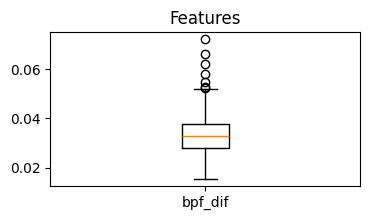

In [2]:
satistics_results = f'{base_path}/statistics/patients/longitudinal/whole_brain_based/features/whole_brains_stats'
cluster_by = ["bpf_dif"]

exclude_patients = None
reader = FeaturesLoader(satistics_results)
data = reader.get_df(columns=cluster_by.copy(),
                     remove_columns=False, 
                     return_patient_id=True, 
                     id_patients=exclude_patients,
                     remove_patients=True)

data_ids = data.pop('patient_id').tolist()
data_columns = data.columns.tolist()
vis.plot_data_voxplot(data, data_columns, figsize=(4,2))

print("nb_patients:", len(data_ids))
print(int(pil.EXCLUDED_PATIENTS[0]) in data_ids)



# preprocessing

nb NO outlayers: 675
nb outlayers: 28


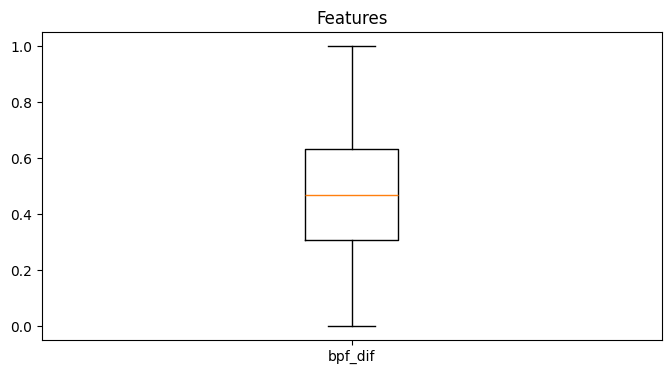

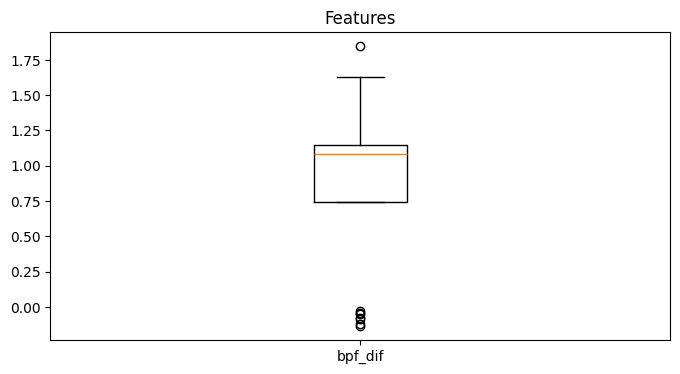

In [3]:
data_no_outlayers, no_outlayers_index, outlayers_index = uml.remove_outliers_zscore(data.values, threshold=2)
data_standardized, standarizer = uml.standarize_columns(data_no_outlayers)
data_normalized, normalizer = uml.normalize_columns(data_standardized)
data_normalized_df = pd.DataFrame(data_normalized, columns=data_columns)
vis.plot_data_voxplot(data_normalized_df, data_columns, figsize=(8,4))

data_outlayers = data.values[outlayers_index]
data_outlayers = standarizer.transform(data_outlayers)
data_outlayers = normalizer.transform(data_outlayers)
data_outlayers_df = pd.DataFrame(data_outlayers, columns=data_columns)
vis.plot_data_voxplot(data_outlayers_df, data_columns, figsize=(8,4))

print("nb NO outlayers:", len(no_outlayers_index))
print("nb outlayers:", len(outlayers_index))


# Clustering

(array([0, 1]), array([349, 326], dtype=int64))


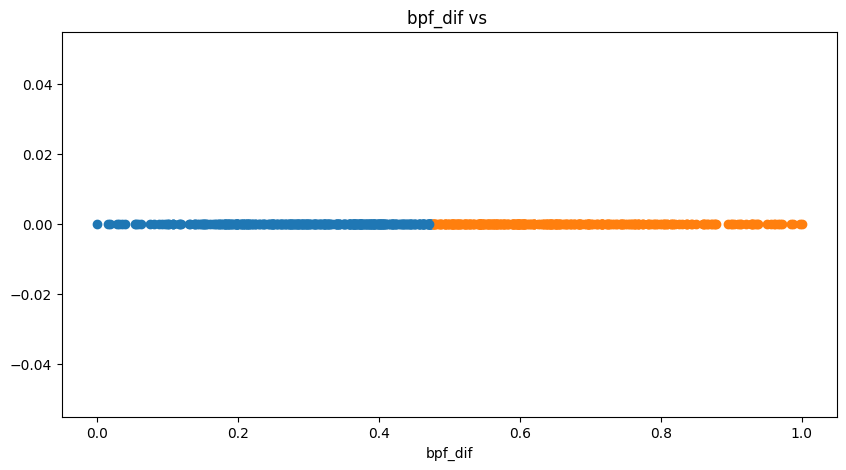

In [4]:
cluster_with_center = False

if cluster_with_center:
    clusters = uml.cluster_by_mean_with_center_df(data_normalized_df, cluster_by, 0.2)
else :
    clusters = uml.cluster_by_mean_df(data_normalized_df, cluster_by)

print(np.unique(clusters, return_counts=True))

vis.visualize_clusters(data_normalized_df, clusters, cluster_by, figsize=(10,5), hist=False)


# Cluster outlayers

(array([0, 1, 4]), array([349, 326,  28], dtype=int64))


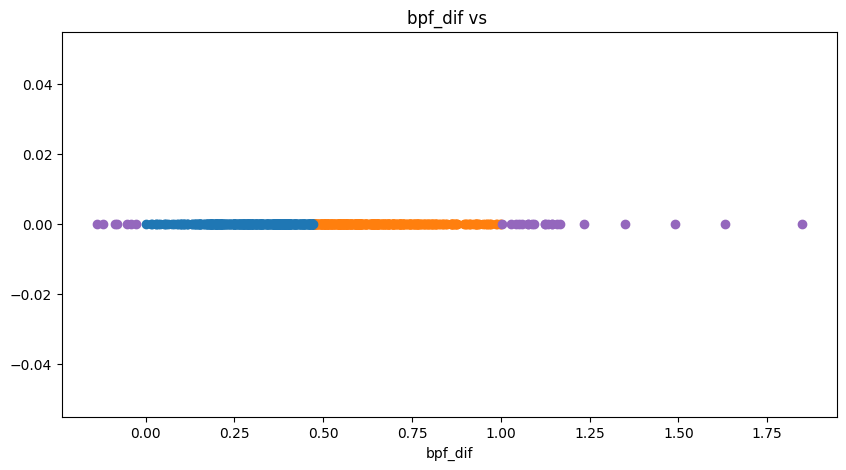

In [5]:
data_concat = np.concatenate([data_normalized, data_outlayers], axis=0)
data_concat_df = pd.DataFrame(data_concat, columns=data_columns)

concatenate_fake_clusters = list(tuple(clusters)+ tuple([4]*len(outlayers_index)))

print(np.unique(concatenate_fake_clusters, return_counts=True))
vis.visualize_clusters(data_concat_df, concatenate_fake_clusters, cluster_by, figsize=(10,5), hist=False)

(array([0, 1]), array([ 7, 21], dtype=int64))


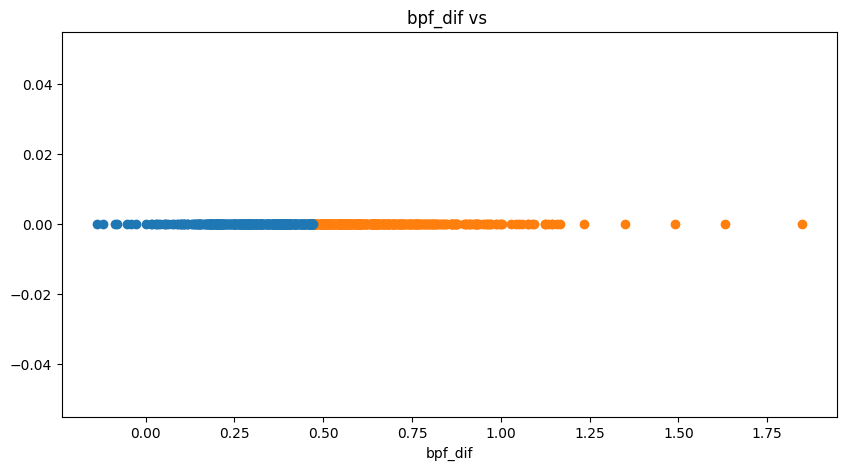

In [6]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=1)
knn.fit(data_normalized_df[cluster_by], clusters)
clusters_outlayers = knn.predict(data_outlayers_df[cluster_by])
concatenate_clusters = list(tuple(clusters)+ tuple(clusters_outlayers))

print(np.unique(clusters_outlayers, return_counts=True))
vis.visualize_clusters(data_concat_df, concatenate_clusters, cluster_by, figsize=(10,5), hist=False)


In [7]:
concatenate_ids = tuple(np.array(data_ids)[no_outlayers_index]) + tuple(np.array(data_ids)[outlayers_index])
df = pd.DataFrame(zip(concatenate_ids,concatenate_clusters), columns=['patient_id', 'bpf_clusters']).astype(int)
ordered_df = df.sort_values(by='patient_id')

print(np.unique(concatenate_clusters, return_counts=True))

name = f"longitudinal_wbb-{'_'.join(cluster_by)}-{len(np.unique(concatenate_clusters))}"
ordered_df.to_csv(f"{current_path}/clusters/{name}.csv", index=False)
print(ordered_df.head())

# [149, 209, 207, 138]
# [ 68,  75, 112,  59,  62,  74, 118,  74,  61]

(array([0, 1]), array([356, 347], dtype=int64))
     patient_id  bpf_clusters
675          39             0
0            46             1
1            53             1
2            77             1
3            91             1
